# SPKLU Coverage Analysis — Indonesia

**Author:** Ryan Farid Pratama

**Tech Stack:** Python, pandas, NumPy, SciPy, Matplotlib, Seaborn, Tableau

**Interactive dashboard (Tableau Public):** https://public.tableau.com/app/profile/ryan.pratama7647/viz/P1M2_ryan_farid/Dashboard1?publish=yes

## Project Overview

This project analyses the spatial inequality of Indonesia's public EV charging network — *Stasiun Pengisian Kendaraan Listrik Umum* (SPKLU). A national geospatial dataset of 2,454 charging stations is cleaned and joined with provincial demographic and economic indicators using pandas, then explored through descriptive and inferential statistics (including Welch t-tests with effect sizes) to quantify how coverage varies across operators and regions. The curated dataset feeds an interactive Tableau dashboard, supporting operator-share, per-capita, per-GRDP, and charging-desert analytics for infrastructure planning by PT PLN and the Ministry of Transportation.

## Analysis Approach

- **Extract:** Load the national SPKLU station table and the BPS provincial coverage table from the Mendeley geospatial dataset (`z2bvd5r574`).
- **Transform:** Clean missing values, validate data types, join the tables on the BPS province code, and derive spatial flags (`deserted`, `java`) using pandas.
- **Analyse:** Answer six key questions with descriptive statistics, cross-tabulations, visualisations, and inferential testing (Welch t-tests reporting p-value, Cohen's d, and 95% CI).
- **Deliver:** Export the curated dataset (`spklu_curated.csv`) and build an interactive Tableau dashboard for operator-share, provincial-coverage, and charging-desert analytics.

## 1. Problem Framing

### 1.1 Background

Through Presidential Regulation No. 55 of 2019, Indonesia committed to accelerating the
transition to battery electric vehicles (BEVs), targeting 15 million EVs on the road by 2030
and a phase-out of internal-combustion vehicle sales by 2050.

Reaching that target depends on the availability and reach of public charging infrastructure
(SPKLU). Rapid EV growth concentrated in major cities raises the risk of spatial accessibility
gaps and "charging deserts" outside the main economic centres. Without an objective spatial
picture of where stations sit, how coverage compares per capita and per unit of GRDP, and how
the roles of the state operator (PT PLN) and private providers are split, infrastructure
investment risks being inefficient and holding back national EV adoption.

### 1.2 Objective

Evaluate and quantify the spatial inequality of SPKLU coverage across Indonesian provinces and
regencies — by distribution, per-100k-population ratio, and per-trillion-Rupiah-GRDP ratio — in
order to identify under-served regions ("charging deserts") and support data-driven planning.

### 1.3 Problem Statement (SMART)

Evaluate the distribution, per-capita and per-GRDP coverage ratios, and spatial charging-desert
map of Indonesia's SPKLU network at the province/regency level, to detect under-served regions
for PT PLN (Persero), using the national 2025/2026 spatial dataset.

| SMART | Detail |
|---|---|
| **Specific** | Assess distribution, per-capita/per-GRDP ratios, and map charging deserts across the SPKLU network. |
| **Measurable** | Stations per 100k population (`stations_per_100k`), stations per trillion Rp GRDP (`stations_per_trillion_gdp`), and share of isolated stations (`nearest_road_km` > 20 km). |
| **Achievable** | Computed by joining the station table (`spklu_stations`) with the BPS provincial coverage table (`spklu_province_coverage`). |
| **Relevant** | Gives PT PLN and the Ministry of Transportation an objective map of under-served areas. |
| **Time-bound** | Based on the national SPKLU spatial dataset for 2025/2026. |

### 1.4 Key Questions

1. **Operator market share** — How are SPKLU stations split between PT PLN, independent private
   CPOs, automaker/dealership networks, and others?
2. **Charging power by location type** — How does the mix of charging power tiers vary across
   location categories (highway corridors, utility sites, retail, etc.)?
3. **Provincial coverage gaps** — Which provinces have the lowest coverage, measured both per
   100k population and per trillion Rupiah of GRDP? (Are they the same provinces?)
4. **Charging deserts** — What share of stations are spatially isolated (more than 20 km by road
   from the nearest other station)?
5. **Descriptive statistics** — What are the central tendency, spread, and outlier structure of
   installed power and inter-station distance across all stations?
6. **Java vs. non-Java inequality (inferential)** — Is there a statistically significant
   difference in installed power *and* in inter-station distance between Java and the rest of
   Indonesia, and how large is that difference in practical terms?

## 2. Data Loading

### 2.1 Library Imports

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Statistics, hypothesis testing, correlation
import scipy.stats as stats

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Keep notebook output clean
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

### 2.2 Load the Dataset

Source: Mendeley Data — *A Geospatial Dataset of Public Electric Vehicle Charging Stations in
Indonesia*  
URL: https://data.mendeley.com/datasets/z2bvd5r574/2  
Contributors: Richard
Wiputra, Sherly Santiadi (BINUS University)

The dataset ships five tables. To answer the six key questions we use two of them — the station
table and the provincial coverage table — and join them into a single analysis DataFrame.

| Table | Content |
|---|---|
| `spklu_stations` | One row per SPKLU location: name, operator, administrative region, coordinates, power, derived spatial metrics. |
| `spklu_chargers` | Technical specs of individual chargers (power, tier). |
| `spklu_province_coverage` | Province-level coverage plus demographic/economic indicators (population, GRDP, per-capita and per-GRDP ratios). |
| `spklu_province_indicators` | Additional provincial demographic statistics. |
| `spklu_regency_codes` | Reference list of regency/city names and BPS codes. |

In [2]:
# Paths are relative to this notebook at the repository root.
DATA_DIR = "A Geospatial Dataset of Public Electric Vehicle"

stations = pd.read_csv(f"{DATA_DIR}/data/spklu_stations.csv")
coverages = pd.read_csv(f"{DATA_DIR}/reference/spklu_province_coverage.csv")

print(f"stations : {stations.shape[0]} rows x {stations.shape[1]} cols")
print(f"coverages: {coverages.shape[0]} rows x {coverages.shape[1]} cols")

stations : 2454 rows x 44 cols
coverages: 34 rows x 15 cols


### 2.3 Data Exploration

#### 2.3.1 Station table

In [3]:
stations.info()

<class 'pandas.DataFrame'>
RangeIndex: 2454 entries, 0 to 2453
Data columns (total 44 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   station_id                 2454 non-null   int64  
 1   location_name              2454 non-null   str    
 2   address                    2451 non-null   str    
 3   provider_type              2454 non-null   str    
 4   operator_brand             821 non-null    str    
 5   location_type              2454 non-null   str    
 6   location_group             2454 non-null   str    
 7   province_name              2454 non-null   str    
 8   bps_province_code          2454 non-null   int64  
 9   regency_city_raw           2454 non-null   str    
 10  regency_city_clean         2454 non-null   str    
 11  admin_level                2454 non-null   str    
 12  bps_regency_code           2454 non-null   int64  
 13  latitude                   2454 non-null   float64
 14  lon

**Notes:** the station table holds 2,454 rows across 44 columns. Several columns carry
missing values — most notably `operator_brand` (1,633 blanks) and the `stations_within_*`
neighbour lists — which is expected because not every station reports a brand or has neighbours
within the given radius.

In [4]:
stations.head(5)

,station_id,location_name,address,provider_type,operator_brand,location_type,location_group,province_name,bps_province_code,regency_city_raw,...,stations_within_1km_ids,stations_within_3km,stations_within_3km_names,stations_within_3km_ids,stations_within_5km,stations_within_5km_names,stations_within_5km_ids,local_density_1km,local_density_3km,local_density_5km
0,4,SPKLU Tangcity,"Jl. Jenderal Sudirman No.1, Cikokol",PLN / SPKLU network,NaN,Mall / Shopping,Retail & Commercial,Banten,36,Kota Tangerang,...,2408|1663|1885,15,AUTO2000 Tangerang|SPKLU Eco Business Park|Ast...,2408|811|2143|2286|1663|638|1885|2493|382|2658...,29,AUTO2000 Tangerang|SPKLU Eco Business Park|Ast...,2408|811|2143|2286|1663|414|638|3|1885|2493|22...,0.95,0.53,0.37
1,6,SPKLU PLN ULP Medan Kota,Jl. Listrik No. 8 Medan,PLN / SPKLU network,NaN,PLN / Utility facility,Utility (PLN site),Sumatera Utara,12,Kota Medan,...,680|2596|795|2165|2963,17,SPKLU CityView Medan|Hyundai SM Raja (Khusus K...,59|2098|2407|680|405|2596|2387|992|981|977|229...,26,SPKLU CityView Medan|(WULING) Arista SM Raja|H...,59|2256|2098|1926|2407|680|405|2596|2387|991|5...,1.59,0.60,0.33
2,9,SPKLU PLN ULP DENPASAR,JL. P.B. Sudirman,PLN / SPKLU network,NaN,PLN / Utility facility,Utility (PLN site),Bali,51,Kota Denpasar,...,1968|1425|303,10,SPKLU DITLANTAS POLDA BALI|SPKLU BANK BTN KC D...,290|1968|63|669|1425|303|2827|1639|1035|353,21,SPKLU DITLANTAS POLDA BALI|(VOLTRON) McDonald'...,290|2917|1968|63|3040|669|2324|1415|2749|731|1...,0.95,0.35,0.27
3,10,SPKLU REST AREA (TRAVOY) KM 519 A Ruas Solo-Ngawi,"Dusun III, Karang Malang, Masaran",Independent CPO,Travoy,Rest area / Toll,Transport corridor,Jawa Tengah,33,Kab Sragen,...,NaN,0,NaN,NaN,0,NaN,NaN,0.00,0.00,0.00
4,13,SPKLU PLN ULP Embong Wungu,"Jl. Dr. Soetomo No. 42,Tegalsari",PLN / SPKLU network,NaN,PLN / Utility facility,Utility (PLN site),Jawa Timur,35,Kota Surabaya,...,2064,11,SPKLU Center Surabaya|(DayaGreen) Hotel Pop Di...,1838|2809|2997|933|2064|2650|60|2458|1362|2605...,22,SPKLU PT PJB|SPKLU HOTEL NARITA SURABAYA|SPKLU...,74|860|2942|2295|2989|1838|2809|2997|2955|2405...,0.32,0.39,0.28


In [5]:
print("Missing values (station table), top columns:")
print(stations.isnull().sum().sort_values(ascending=False).head(10))

Missing values (station table), top columns:
operator_brand               1633
stations_within_1km_names    1357
stations_within_1km_ids      1357
stations_within_3km_names     716
stations_within_3km_ids       716
stations_within_5km_names     560
stations_within_5km_ids       560
address                         3
provider_type                   0
location_type                   0
dtype: int64


In [6]:
print(f"Duplicate rows in station table: {stations.duplicated().sum()}")

Duplicate rows in station table: 0


#### 2.3.2 Provincial coverage table

In [7]:
coverages.info()

<class 'pandas.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   bps_province_code          34 non-null     int64  
 1   province_name              34 non-null     str    
 2   population_sp2020          34 non-null     int64  
 3   grdp_current_idr_billion   34 non-null     int64  
 4   grdp_year                  34 non-null     int64  
 5   bev_registered             0 non-null      float64
 6   n_stations                 34 non-null     int64  
 7   n_chargers                 34 non-null     int64  
 8   n_connectors               34 non-null     int64  
 9   total_installed_kW         34 non-null     float64
 10  stations_per_100k          34 non-null     float64
 11  chargers_per_100k          34 non-null     float64
 12  kW_per_10k                 34 non-null     float64
 13  stations_per_trillion_gdp  34 non-null     float64
 14  charger

In [8]:
coverages.head(5)

,bps_province_code,province_name,population_sp2020,grdp_current_idr_billion,grdp_year,bev_registered,n_stations,n_chargers,n_connectors,total_installed_kW,stations_per_100k,chargers_per_100k,kW_per_10k,stations_per_trillion_gdp,chargers_per_1000_bev
0,11,Aceh,5274871,257502,2025,NaN,30,39,41,1016.0,0.569,0.739,1.926,0.117,NaN
1,12,Sumatera Utara,14799361,1236194,2025,NaN,90,174,149,3571.0,0.608,1.176,2.413,0.073,NaN
2,13,Sumatera Barat,5534472,352189,2025,NaN,64,115,94,1446.0,1.156,2.078,2.613,0.182,NaN
3,14,Riau,6394087,1201384,2025,NaN,40,40,56,1479.0,0.626,0.626,2.313,0.033,NaN
4,15,Jambi,3548228,349663,2025,NaN,23,32,29,965.0,0.648,0.902,2.720,0.066,NaN


In [9]:
print(f"Duplicate rows in coverage table: {coverages.duplicated().sum()}")

Duplicate rows in coverage table: 0


## 3. Data Cleaning

We select the key columns from each table and join them on the BPS province code. The join is a
left join keyed on `bps_province_code`, which is unique per province in the coverage table, so the
row count of the station table must be preserved (no fan-out).

In [10]:
station_cols = [
    "station_id", "location_name", "location_group", "provider_type", "operator_brand",
    "province_name", "bps_province_code", "regency_city_clean", "bps_regency_code",
    "latitude", "longitude", "station_power_kW", "station_power_tier",
    "type_charge_source", "nearest_road_km",
]
coverage_cols = [
    "bps_province_code", "population_sp2020", "grdp_current_idr_billion",
    "stations_per_100k", "stations_per_trillion_gdp",
]

spklu = pd.merge(stations[station_cols], coverages[coverage_cols],
                 on="bps_province_code", how="left")
spklu.head()

,station_id,location_name,location_group,provider_type,operator_brand,province_name,bps_province_code,regency_city_clean,bps_regency_code,latitude,longitude,station_power_kW,station_power_tier,type_charge_source,nearest_road_km,population_sp2020,grdp_current_idr_billion,stations_per_100k,stations_per_trillion_gdp
0,4,SPKLU Tangcity,Retail & Commercial,PLN / SPKLU network,NaN,Banten,36,Kota Tangerang,3671,-6.193182,106.633549,25.0,DC fast (25-49 kW),medium,0.98,11904562,936204,1.898,0.241
1,6,SPKLU PLN ULP Medan Kota,Utility (PLN site),PLN / SPKLU network,NaN,Sumatera Utara,12,Kota Medan,1275,3.585722,98.676141,30.0,DC fast (25-49 kW),medium,1.39,14799361,1236194,0.608,0.073
2,9,SPKLU PLN ULP DENPASAR,Utility (PLN site),PLN / SPKLU network,NaN,Bali,51,Kota Denpasar,5171,-8.662908,115.217891,30.0,DC fast (25-49 kW),medium,0.91,4317404,324149,2.432,0.324
3,10,SPKLU REST AREA (TRAVOY) KM 519 A Ruas Solo-Ngawi,Transport corridor,Independent CPO,Travoy,Jawa Tengah,33,Kabupaten Sragen,3314,-7.480695,110.919125,50.0,DC rapid (50-99 kW),fast,13.86,36516035,1943188,0.539,0.101
4,13,SPKLU PLN ULP Embong Wungu,Utility (PLN site),PLN / SPKLU network,NaN,Jawa Timur,35,Kota Surabaya,3578,-7.281320,112.739942,25.0,DC fast (25-49 kW),medium,2.12,40665696,3403167,0.487,0.058


In [11]:
# Validate the join: the row count must be unchanged (no key duplication).
print(f"Rows before merge (stations): {len(stations)}")
print(f"Rows after merge            : {len(spklu)}")
assert len(stations) == len(spklu), "Row count changed - check for duplicate keys!"
print("Merge OK: row count preserved, no key fan-out.")

Rows before merge (stations): 2454
Rows after merge            : 2454
Merge OK: row count preserved, no key fan-out.


In [12]:
print("Missing values after merge:")
print(spklu.isnull().sum()[lambda s: s > 0])

Missing values after merge:
operator_brand    1633
dtype: int64


**Note on missing values:** after the merge, only `operator_brand` still carries missing
values (1,633 rows). We keep the column as-is rather than impute it: a blank brand simply means
the station's operator brand was not recorded, and none of the six key questions depend on the
brand field. No rows are dropped.

## 4. Analysis

### 4.1 Key Question 1 — Operator Market Share

*How are SPKLU stations split between PT PLN, independent private CPOs, automaker/dealership
networks, and others?*

In [13]:
kq1_counts = spklu["provider_type"].value_counts()
kq1_pct = spklu["provider_type"].value_counts(normalize=True) * 100
kq1_df = pd.DataFrame({"Stations": kq1_counts, "Share (%)": kq1_pct.round(2)})
print("SPKLU OPERATOR MARKET SHARE")
display(kq1_df)

SPKLU OPERATOR MARKET SHARE


,Stations,Share (%)
provider_type,,
PLN / SPKLU network,1607,65.48
Independent CPO,470,19.15
Automaker / dealership,351,14.30
Other / unknown,26,1.06


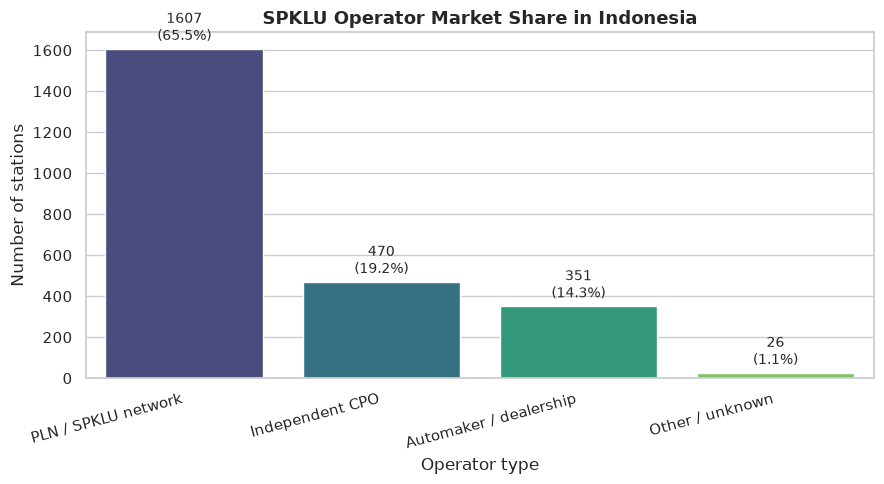

In [14]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(x=kq1_df.index, y=kq1_df["Stations"], palette="viridis")
plt.title("SPKLU Operator Market Share in Indonesia", fontsize=13, fontweight="bold")
plt.xlabel("Operator type")
plt.ylabel("Number of stations")
plt.xticks(rotation=15, ha="right")

# Label each bar with its count and its true share of ALL stations.
total = len(spklu)
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)}\n({h / total * 100:.1f}%)",
                (p.get_x() + p.get_width() / 2., h),
                ha="center", va="bottom", fontsize=10,
                xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

**Insight**

1. PT PLN dominates the network with **65.5%** of stations (1,607), confirming the state utility
   as the primary driver of basic EV-charging infrastructure.
2. Private providers play a supporting role: independent CPOs hold **19.2%** (470 stations) and
   automaker/dealership networks **14.3%** (351). A small **1.1%** (26 stations) fall into an
   *Other / unknown* category and are reported here for completeness rather than dropped.
3. The heavy reliance on a single state operator means national coverage is effectively
   PLN's build-out plan — a structural point that recurs in the regional-gap analysis below.

### 4.2 Key Question 2 — Charging Power by Location Type

*How does the mix of charging power tiers vary across location categories?*

In [15]:
kq2_counts = pd.crosstab(spklu["location_group"], spklu["station_power_tier"])
print("LOCATION GROUP vs POWER TIER (counts)")
display(kq2_counts)

LOCATION GROUP vs POWER TIER (counts)


station_power_tier,AC fast (11-22 kW),AC slow (<=7 kW),DC fast (25-49 kW),DC rapid (50-99 kW),DC ultra-rapid (>=100 kW)
location_group,,,,,
Hospitality,133,28,3,7,6
Office & Residential,169,8,22,17,15
Other / Unclassified,327,44,39,54,53
Public & Civic,107,15,13,19,10
Retail & Commercial,241,119,24,147,35
Transport corridor,17,2,6,42,46
Utility (PLN site),407,68,91,82,38


In [16]:
kq2_pct = pd.crosstab(spklu["location_group"], spklu["station_power_tier"],
                      normalize="index") * 100
display(kq2_pct.round(1))

station_power_tier,AC fast (11-22 kW),AC slow (<=7 kW),DC fast (25-49 kW),DC rapid (50-99 kW),DC ultra-rapid (>=100 kW)
location_group,,,,,
Hospitality,75.1,15.8,1.7,4.0,3.4
Office & Residential,73.2,3.5,9.5,7.4,6.5
Other / Unclassified,63.2,8.5,7.5,10.4,10.3
Public & Civic,65.2,9.1,7.9,11.6,6.1
Retail & Commercial,42.6,21.0,4.2,26.0,6.2
Transport corridor,15.0,1.8,5.3,37.2,40.7
Utility (PLN site),59.3,9.9,13.3,12.0,5.5


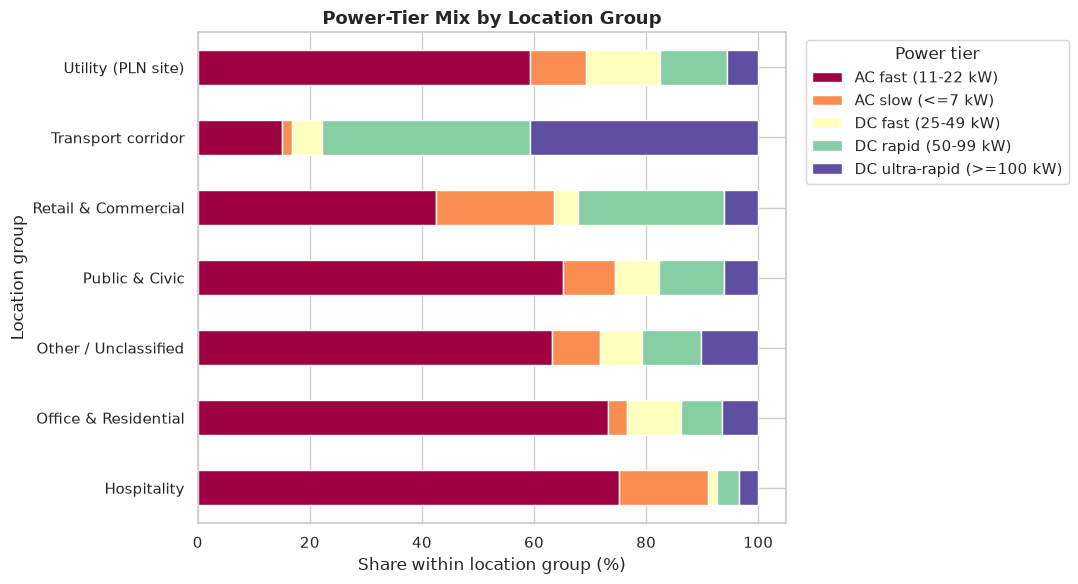

In [17]:
ax = kq2_pct.plot(kind="barh", stacked=True, figsize=(11, 6), colormap="Spectral")
plt.title("Power-Tier Mix by Location Group", fontsize=13, fontweight="bold")
plt.xlabel("Share within location group (%)")
plt.ylabel("Location group")
plt.legend(title="Power tier", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Insight**

1. **Transport corridors** (e.g. toll-road rest areas) are heavily skewed toward fast charging:
   roughly 78% of their stations are DC Rapid or DC Ultra-rapid, which makes sense for minimising
   dwell time on long trips.
2. **Utility (PLN) sites** carry the largest absolute volume across almost every tier, especially
   AC Fast, serving everyday top-up charging for the general public.
3. Lower-power AC tiers cluster in retail and commercial locations, consistent with longer
   dwell times (shopping, parking) where slower charging is acceptable.

### 4.3 Key Question 3 — Provincial Coverage Gaps

*Which provinces have the lowest coverage, measured both per 100k population and per trillion
Rupiah of GRDP — and are they the same provinces?*

Because `stations_per_100k` and `stations_per_trillion_gdp` are province-level constants merged
onto each station, we take one value per province (`.first()`), then rank on **both** metrics.

In [18]:
prov = (spklu.groupby("province_name")[["stations_per_100k", "stations_per_trillion_gdp"]]
        .first()
        .reset_index())

print("LOWEST 5 PROVINCES BY STATIONS PER 100k POPULATION")
display(prov.sort_values("stations_per_100k").head(5).reset_index(drop=True))

print("LOWEST 5 PROVINCES BY STATIONS PER TRILLION Rp GRDP")
display(prov.sort_values("stations_per_trillion_gdp").head(5).reset_index(drop=True))

LOWEST 5 PROVINCES BY STATIONS PER 100k POPULATION


,province_name,stations_per_100k,stations_per_trillion_gdp
0,Papua,0.349,0.048
1,Lampung,0.389,0.067
2,Sulawesi Tenggara,0.419,0.054
3,Kepulauan Riau,0.484,0.026
4,Jawa Timur,0.487,0.058


LOWEST 5 PROVINCES BY STATIONS PER TRILLION Rp GRDP


,province_name,stations_per_100k,stations_per_trillion_gdp
0,Kepulauan Riau,0.484,0.026
1,Kalimantan Utara,0.712,0.032
2,Riau,0.626,0.033
3,Sulawesi Tengah,0.603,0.043
4,Papua,0.349,0.048


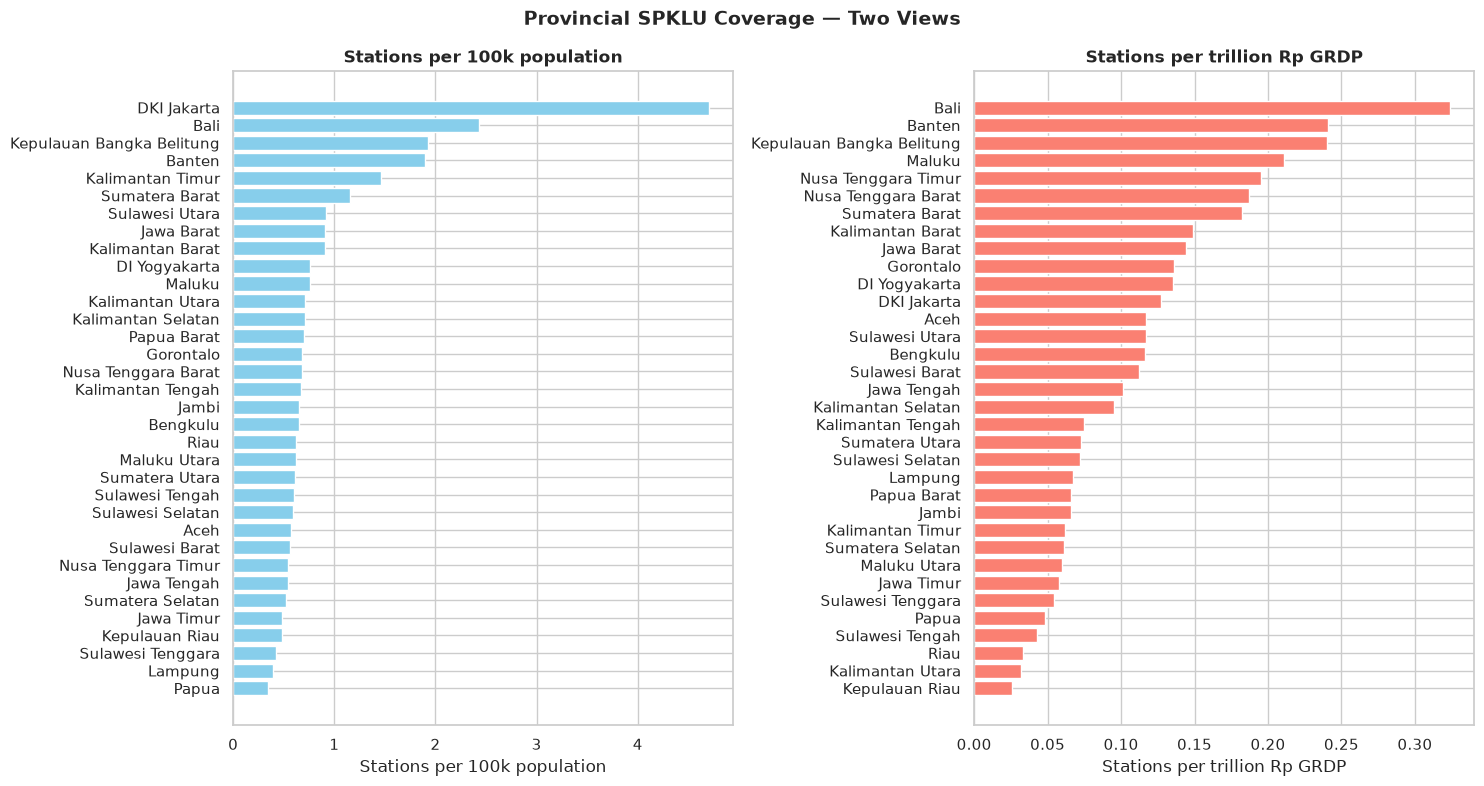

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=False)

# Panel A: per 100k population
a = prov.sort_values("stations_per_100k")
axes[0].barh(a["province_name"], a["stations_per_100k"], color="skyblue")
axes[0].set_title("Stations per 100k population", fontweight="bold")
axes[0].set_xlabel("Stations per 100k population")

# Panel B: per trillion Rp GRDP
b = prov.sort_values("stations_per_trillion_gdp")
axes[1].barh(b["province_name"], b["stations_per_trillion_gdp"], color="salmon")
axes[1].set_title("Stations per trillion Rp GRDP", fontweight="bold")
axes[1].set_xlabel("Stations per trillion Rp GRDP")

fig.suptitle("Provincial SPKLU Coverage — Two Views", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight**

1. **The two rankings disagree**, which is the main point of asking both. The lowest-coverage
   provinces *per capita* are Papua (0.35), Lampung (0.39), Sulawesi Tenggara (0.42), Kepulauan
   Riau (0.48) and Jawa Timur (0.49). The lowest *per GRDP* are Kepulauan Riau (0.026), Kalimantan
   Utara (0.032), Riau (0.033), Sulawesi Tengah (0.043) and Papua (0.048).
2. Only **Papua and Kepulauan Riau appear on both lists** — they are under-served no matter how
   you normalise. Provinces like Riau and Kalimantan Utara look adequate per capita but lag badly
   relative to the economic activity they generate, suggesting infrastructure that has not kept up
   with local economic weight.
3. For context, the best-covered provinces per capita are DKI Jakarta (4.71), Bali (2.43) and
   Kepulauan Bangka Belitung (1.92) — coverage is concentrated in the capital and in tourism hubs,
   while much of Sumatra, Sulawesi, Kalimantan and Papua sits below 1 station per 100k.

> **Note on the "global benchmark":** an earlier version compared provinces to a fixed "25 per
> 100k" global target. That figure is not sourced in this dataset, so it is omitted here. Any such
> benchmark should cite a credible source before being used to make a headline claim.

### 4.4 Key Question 4 — Charging Deserts

*What share of stations are spatially isolated — more than 20 km by road from the nearest other
station?*

**Definition (from the dataset's data dictionary):** `nearest_road_km` is the *road-network
driving distance in km to the nearest **other** station*, computed via OSRM over OpenStreetMap.
A station is flagged as a **charging desert** here if that distance exceeds 20 km — i.e. it has no
alternative station within a reasonable detour, which is what creates range-anxiety risk.

In [20]:
spklu["deserted"] = spklu["nearest_road_km"] > 20
desert_counts = spklu["deserted"].value_counts()
desert_pct = spklu["deserted"].value_counts(normalize=True) * 100
print("CHARGING DESERTS (>20 km to nearest other station)")
print(f"Isolated (>20 km)   : {desert_counts.get(True, 0)} stations ({desert_pct.get(True, 0):.2f}%)")
print(f"Connected (<=20 km) : {desert_counts.get(False, 0)} stations ({desert_pct.get(False, 0):.2f}%)")

CHARGING DESERTS (>20 km to nearest other station)
Isolated (>20 km)   : 337 stations (13.73%)
Connected (<=20 km) : 2117 stations (86.27%)


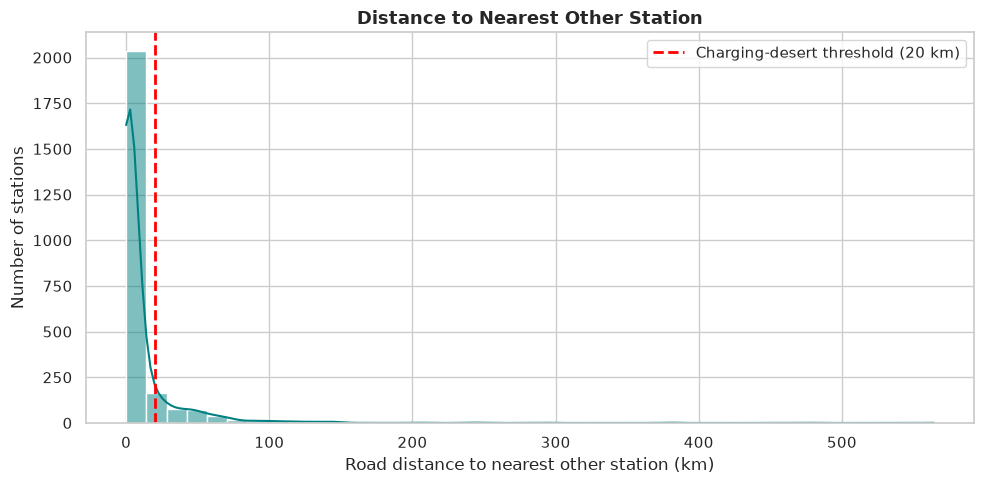

In [21]:
plt.figure(figsize=(10, 5))
sns.histplot(spklu["nearest_road_km"], bins=40, kde=True, color="teal")
plt.axvline(x=20, color="red", linestyle="--", linewidth=2,
            label="Charging-desert threshold (20 km)")
plt.title("Distance to Nearest Other Station", fontsize=13, fontweight="bold")
plt.xlabel("Road distance to nearest other station (km)")
plt.ylabel("Number of stations")
plt.legend()
plt.tight_layout()
plt.show()

**Insight**

1. **13.73% (337 stations)** are charging deserts — more than 20 km by road from any other station.
   The remaining 86.27% (2,117) sit within a connected network.
2. The distribution is sharply right-skewed: most stations are clustered within a few km of a
   neighbour (urban and activity centres), while a long tail stretches to hundreds of km.
3. **Caveat on interpretation:** this is a *station-level* isolation measure. A fuller "charging
   desert" definition would also look at the *regional* level — provinces or regencies with no or
   very low coverage — since an isolated individual station and an entirely un-served district are
   different planning problems. The regional view in Key Question 3 complements this one.

### 4.5 Key Question 5 — Descriptive Statistics

*What are the central tendency, spread, and outlier structure of installed power and
inter-station distance across all stations?*

In [22]:
def describe_column(series, name):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < low) | (s > high)).sum())
    return {
        "Mean": round(s.mean(), 2), "Median": round(s.median(), 2),
        "Std dev": round(s.std(), 2), "Q1": round(q1, 2), "Q3": round(q3, 2),
        "IQR": round(iqr, 2), "Outlier low": round(low, 2), "Outlier high": round(high, 2),
        "# Outliers": n_out, "Skew": round(s.skew(), 2),
    }

summary = pd.DataFrame({
    "Installed power (kW)": describe_column(spklu["station_power_kW"], "power"),
    "Nearest-station distance (km)": describe_column(spklu["nearest_road_km"], "distance"),
})
print("DESCRIPTIVE STATISTICS")
display(summary)

DESCRIPTIVE STATISTICS


,Installed power (kW),Nearest-station distance (km)
Mean,36.62,10.86
Median,22.00,2.09
Std dev,40.45,29.26
Q1,22.00,0.98
Q3,30.00,6.91
IQR,8.00,5.93
Outlier low,10.00,-7.91
Outlier high,42.00,15.80
# Outliers,866.00,393.00
Skew,4.86,8.44


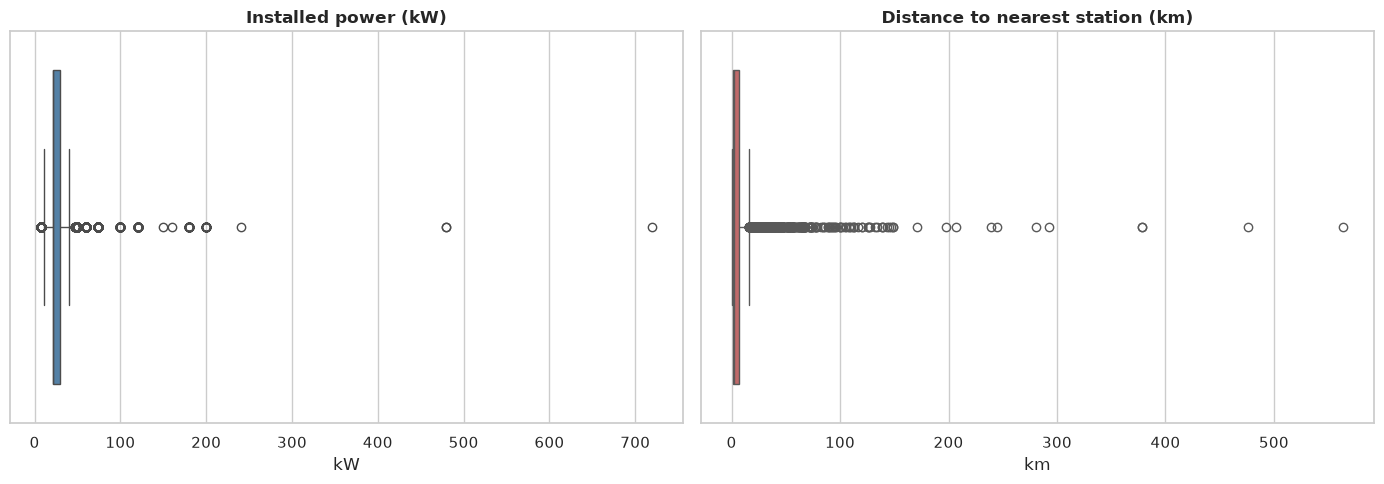

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=spklu["station_power_kW"], ax=axes[0], color="steelblue")
axes[0].set_title("Installed power (kW)", fontweight="bold")
axes[0].set_xlabel("kW")
sns.boxplot(x=spklu["nearest_road_km"], ax=axes[1], color="indianred")
axes[1].set_title("Distance to nearest station (km)", fontweight="bold")
axes[1].set_xlabel("km")
plt.tight_layout()
plt.show()

**Insight**

1. **Installed power** is strongly right-skewed (skew ≈ 4.9). The median is **22 kW** versus a mean
   of **36.6 kW**, and the IQR is tight (22–30 kW), so a typical station is a modest AC/entry-level
   DC unit while a minority of high-power DC units pull the mean up. There are **866 statistical
   outliers** above ~42 kW — these are the fast/ultra-rapid DC stations.
2. **Inter-station distance** is even more skewed (skew ≈ 8.4). The median is just **2.1 km** but
   the mean is **10.9 km**, with a huge standard deviation (29.3 km): most stations sit very close
   to a neighbour, while **393 outliers** stretch far beyond the ~15.8 km upper fence — these are
   the isolated stations behind the charging-desert finding.
3. Both variables are therefore better summarised by the **median than the mean**, and the heavy
   right tails are exactly where the policy-relevant cases (high-power hubs; isolated stations)
   live.

### 4.6 Key Question 6 — Java vs. non-Java Inequality (Inferential)

*Is there a statistically significant difference in installed power **and** in inter-station
distance between Java and the rest of Indonesia — and how large is the difference in practical
terms?*

We run two independent two-sample **Welch t-tests** (unequal variances), one per variable, and
report the **effect size (Cohen's d)** and a **95% confidence interval** for the mean difference
alongside the p-value, so we can judge practical as well as statistical significance.

In [24]:
java_provinces = ["DKI Jakarta", "Jawa Barat", "Jawa Tengah",
                   "DI Yogyakarta", "Jawa Timur", "Banten"]
spklu["java"] = spklu["province_name"].isin(java_provinces)

share_java = spklu["java"].mean() * 100
print(f"Java      : {int(spklu['java'].sum())} stations ({share_java:.1f}%)")
print(f"Non-Java  : {int((~spklu['java']).sum())} stations ({100 - share_java:.1f}%)")

Java      : 1583 stations (64.5%)
Non-Java  : 871 stations (35.5%)


**Hypotheses** (tested separately for installed power and for inter-station distance):

- **H₀:** the mean (power / distance) is equal between Java and non-Java stations.
- **H₁:** the mean (power / distance) differs between Java and non-Java stations.
- Significance level **α = 0.05**.

In [25]:
def welch_report(group_a, group_b, label_a="Java", label_b="non-Java"):
    a, b = group_a.dropna(), group_b.dropna()
    t, p = stats.ttest_ind(a, b, equal_var=False)
    # Pooled SD for Cohen's d
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var() + (nb - 1) * b.var()) / (na + nb - 2))
    d = (a.mean() - b.mean()) / sp
    # Welch 95% CI for the difference in means
    se = np.sqrt(a.var() / na + b.var() / nb)
    dof = (a.var() / na + b.var() / nb) ** 2 / (
        (a.var() / na) ** 2 / (na - 1) + (b.var() / nb) ** 2 / (nb - 1))
    tcrit = stats.t.ppf(0.975, dof)
    diff = a.mean() - b.mean()
    ci = (diff - tcrit * se, diff + tcrit * se)
    return {
        f"mean_{label_a}": round(a.mean(), 2), f"mean_{label_b}": round(b.mean(), 2),
        "t": round(t, 3), "p_value": p, "cohens_d": round(d, 3),
        "mean_diff": round(diff, 2), "CI95_low": round(ci[0], 2), "CI95_high": round(ci[1], 2),
    }

power = welch_report(spklu[spklu["java"]]["station_power_kW"],
                     spklu[~spklu["java"]]["station_power_kW"])
dist = welch_report(spklu[spklu["java"]]["nearest_road_km"],
                    spklu[~spklu["java"]]["nearest_road_km"])

results = pd.DataFrame({"Installed power (kW)": power,
                        "Nearest-station distance (km)": dist})
print("WELCH t-TEST RESULTS  (alpha = 0.05)")
display(results)

WELCH t-TEST RESULTS  (alpha = 0.05)


,Installed power (kW),Nearest-station distance (km)
mean_Java,38.650000,3.740000e+00
mean_non-Java,32.930000,2.379000e+01
t,3.707000,-1.291400e+01
p_value,0.000215,4.255691e-35
cohens_d,0.142000,-7.250000e-01
mean_diff,5.720000,-2.004000e+01
CI95_low,2.690000,-2.309000e+01
CI95_high,8.750000,-1.700000e+01


In [26]:
alpha = 0.05
def effect_label(d):
    d = abs(d)
    return ("negligible" if d < 0.2 else "small" if d < 0.5
            else "medium" if d < 0.8 else "large")

for name, res in [("Installed power", power), ("Nearest-station distance", dist)]:
    decision = "REJECT H0" if res["p_value"] < alpha else "FAIL TO REJECT H0"
    print(f"{name}: {decision}  (p = {res['p_value']:.3e}, "
          f"Cohen's d = {res['cohens_d']:.3f} -> {effect_label(res['cohens_d'])} effect)")

Installed power: REJECT H0  (p = 2.150e-04, Cohen's d = 0.142 -> negligible effect)
Nearest-station distance: REJECT H0  (p = 4.256e-35, Cohen's d = -0.725 -> medium effect)


**Insight**

1. **Installed power — statistically significant but practically negligible.** We reject H₀
   (t = 3.71, p ≈ 2.2×10⁻⁴), but the effect size is tiny: **Cohen's d ≈ 0.14**. Java stations
   average 38.65 kW vs 32.93 kW off-Java — a 5.7 kW difference (95% CI ≈ [2.7, 8.8]). With n = 2,454
   even trivial gaps reach significance, so this difference, while real, is not a strong basis for
   a "mass upgrade to DC Fast" recommendation on its own.
2. **Inter-station distance — significant *and* substantial.** We reject H₀ decisively
   (t = −12.9, p ≈ 4×10⁻³⁵) with a **medium-to-large effect (Cohen's d ≈ −0.73)**. Java stations
   sit on average **3.7 km** from a neighbour versus **23.8 km** off-Java — a ~20 km gap
   (95% CI ≈ [−23.1, −17.0]). This is the real inequality story: the problem outside Java is far
   more about **spatial coverage and connectivity** than about per-station power.
3. On volume, **64.5% of all stations (1,583) are in Java.** The strategic implication is to
   prioritise *new stations to close distance gaps* off-Java, rather than chiefly upgrading the
   power of existing ones.

## 5. Conclusion

### 5.1 Findings (technical)

1. **Operator structure.** PT PLN owns 65.5% of SPKLU stations (1,607); independent CPOs 19.2%
   (470) and automaker/dealership networks 14.3% (351), with 1.1% other. National coverage is
   effectively PLN's build-out.
2. **Regional inequality.** Per-capita and per-GRDP rankings disagree, but **Papua and Kepulauan
   Riau are under-served on both**. Coverage concentrates in DKI Jakarta and Bali.
3. **Java vs non-Java.** The gap is driven by **spatial coverage, not power**: distance to the
   nearest station differs by ~20 km (Cohen's d ≈ −0.73, p ≈ 4×10⁻³⁵), while the installed-power
   difference, though significant, is practically negligible (d ≈ 0.14).
4. **Charging deserts.** 13.73% of stations (337) are more than 20 km from any neighbour, raising
   range-anxiety and network-resilience risk, concentrated outside Java.

### 5.2 In plain language (for a general audience)

Indonesia's public EV-charging network is still young and run mainly by the state utility, PLN.
Charging points are crowded into Jakarta, Bali and other big centres, while much of the country —
especially Papua, parts of Sumatra, Kalimantan, Sulawesi and Eastern Indonesia — has very few.
The biggest problem outside Java is not that the chargers there are weaker (they're only slightly
so); it's that they are **too far apart**. On average you'd drive about 20 km further to reach the
next charger outside Java than within it, and about one in seven stations nationwide has no other
charger within 20 km. That distance — not charger power — is what makes long EV trips risky
outside Java.

### 5.3 Recommendations

1. **Prioritise closing distance gaps off-Java.** Build *new* stations along inter-city corridors
   and in isolated areas to add network redundancy and connectivity — this is supported by the
   large distance effect size, whereas a blanket power upgrade is not supported by the data.
2. **Target the doubly under-served provinces first** (Papua, Kepulauan Riau), then provinces that
   lag relative to their economic weight (Riau, Kalimantan Utara).
3. **Treat power upgrades as secondary and targeted** — focus higher-power DC on transport
   corridors where fast charging genuinely matters, rather than a uniform national upgrade.

## 6. Export Curated Dataset

Export the joined, cleaned DataFrame (including the derived `deserted` and `java` flags) for the
Tableau dashboard.

In [27]:
spklu.to_csv("spklu_curated.csv", index=False)
print(f"Exported spklu_curated.csv ({spklu.shape[0]} rows x {spklu.shape[1]} cols)")

Exported spklu_curated.csv (2454 rows x 21 cols)
